In [2]:
import pandas as pd
import matplotlib.pyplot as plt

print("Proyecto CineMetrics iniciado correctamente")

Proyecto CineMetrics iniciado correctamente


# CineMetrics — Impacto y tendencias

## Caso 2: A Minecraft Movie (2025)

### Objetivo
Analizar la evolución del interés de búsqueda por la película
antes y después de su estreno, identificar picos relacionados
con fenómenos virales y generar recomendaciones para CineMetrics.

### Fuente
Google Trends — enero a julio de 2025.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path


In [9]:

ruta = Path(
    r"C:\Codigo\GRUPO-6-CLASE-13-14\IMPTendencia\multiTimeline (2).csv"
)

df = pd.read_csv(ruta, skiprows=1)

display(df.head())

,Día,A Minecraft Movie: (En todo el mundo)
0,2025-01-01,1
1,2025-01-02,1
2,2025-01-03,1
3,2025-01-04,1
4,2025-01-05,1


In [3]:

print("Dimensiones:", df.shape)


print("Columnas:", df.columns.tolist())


df.info()

display(df.head(10))

Dimensiones: (68, 2)
Columnas: ['Semana', 'A Minecraft Movie: (En todo el mundo)']
<class 'pandas.DataFrame'>
RangeIndex: 68 entries, 0 to 67
Data columns (total 2 columns):
 #   Column                                 Non-Null Count  Dtype
---  ------                                 --------------  -----
 0   Semana                                 68 non-null     str  
 1   A Minecraft Movie: (En todo el mundo)  68 non-null     int64
dtypes: int64(1), str(1)
memory usage: 1.2 KB


,Semana,A Minecraft Movie: (En todo el mundo)
0,2025-07-27,66
1,2025-08-03,58
2,2025-08-10,60
3,2025-08-17,56
4,2025-08-24,48
5,2025-08-31,49
6,2025-09-07,47
7,2025-09-14,45
8,2025-09-21,46
9,2025-09-28,47


In [10]:
# Renombrar columnas
df.columns = ["fecha", "interes"]

# Convertir las fechas
df["fecha"] = pd.to_datetime(df["fecha"])

# Identificar valores inferiores a 1
df["interes"] = (
    df["interes"]
    .astype(str)
    .str.replace("\u00a0", " ", regex=False)
    .str.strip()
    .replace("< 1", "0")
)

# Convertir interés a números
df["interes"] = pd.to_numeric(df["interes"])

# Ordenar cronológicamente
df = df.sort_values("fecha").reset_index(drop=True)

# Validaciones
print("Valores nulos:", df.isnull().sum().sum())
print("Duplicados:", df.duplicated().sum())
print("Registros:", len(df))

display(df.head())

Valores nulos: 0
Duplicados: 0
Registros: 212


,fecha,interes
0,2025-01-01,1
1,2025-01-02,1
2,2025-01-03,1
3,2025-01-04,1
4,2025-01-05,1


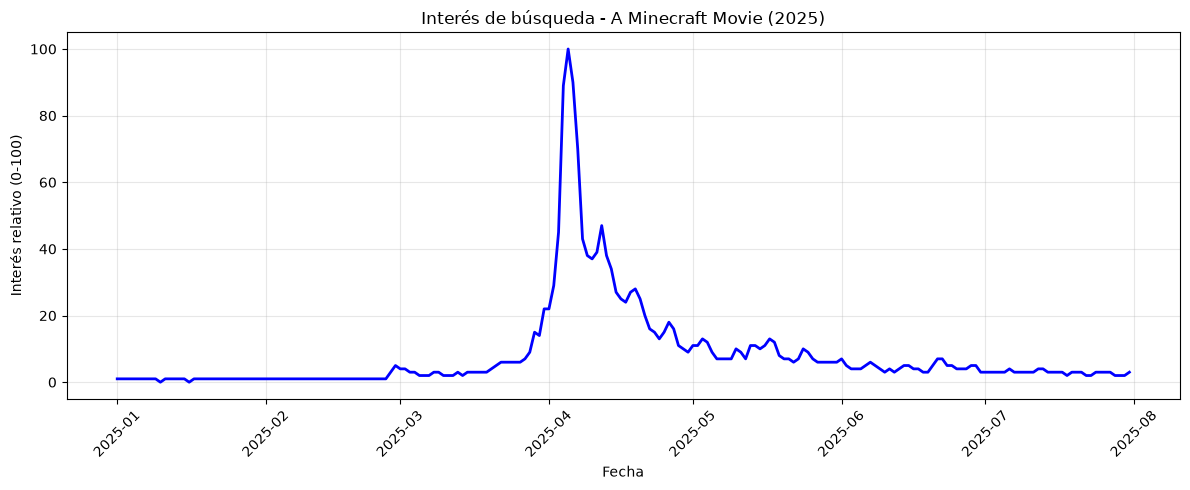

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    df["fecha"],
    df["interes"],
    color="blue",
    linewidth=2
)

plt.title("Interés de búsqueda - A Minecraft Movie (2025)")
plt.xlabel("Fecha")
plt.ylabel("Interés relativo (0-100)")

plt.grid(alpha=0.3)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

El análisis de Google Trends evidencia un incremento significativo del interés de búsqueda por A Minecraft Movie durante abril de 2025, alcanzando su máximo el 5 de abril. Posteriormente, se observa una disminución progresiva del interés. Este comportamiento sugiere una fuerte concentración de atención alrededor del estreno, aunque es necesario investigar los acontecimientos asociados para explicar los picos registrados.

In [12]:
# Obtener los 10 días con mayor interés
top_10 = df.nlargest(10, "interes")

# Mostrar solamente las fechas y sus valores
display(top_10[["fecha", "interes"]])

,fecha,interes
94,2025-04-05,100
95,2025-04-06,90
93,2025-04-04,89
96,2025-04-07,70
101,2025-04-12,47
92,2025-04-03,45
97,2025-04-08,43
100,2025-04-11,39
98,2025-04-09,38
102,2025-04-13,38


In [13]:
# Fecha de estreno
estreno = pd.Timestamp("2025-04-04")

# Separar los datos en dos períodos
antes = df[df["fecha"] < estreno]
despues = df[df["fecha"] >= estreno]

# Calcular el interés promedio
promedio_antes = antes["interes"].mean()
promedio_despues = despues["interes"].mean()

print("Promedio antes del estreno:", round(promedio_antes, 2))
print("Promedio desde el estreno:", round(promedio_despues, 2))

Promedio antes del estreno: 3.41
Promedio desde el estreno: 11.92


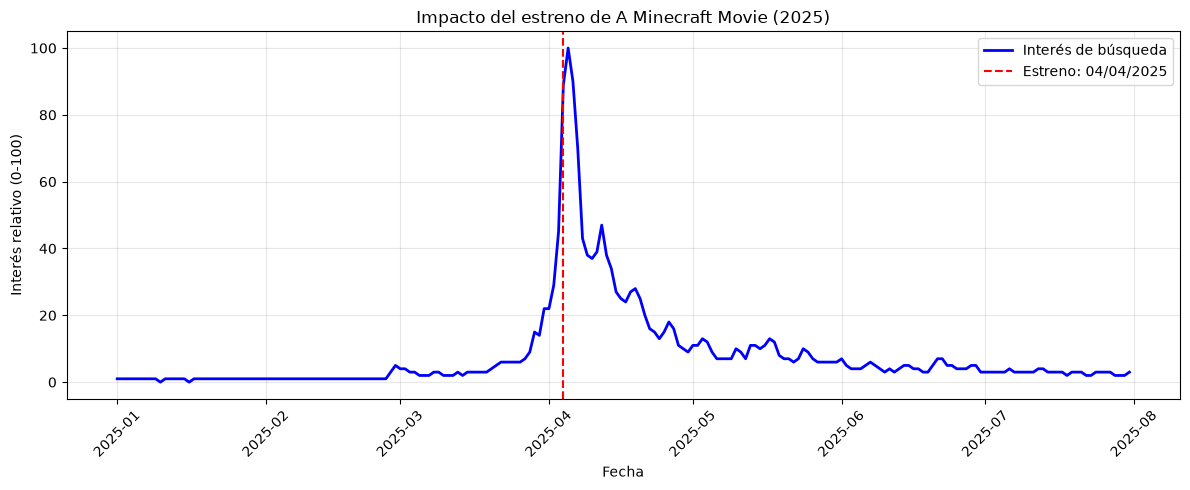

In [14]:
plt.figure(figsize=(12, 5))

plt.plot(
    df["fecha"],
    df["interes"],
    color="blue",
    linewidth=2,
    label="Interés de búsqueda"
)

# Línea que marca el estreno
plt.axvline(
    estreno,
    color="red",
    linestyle="--",
    label="Estreno: 04/04/2025"
)

plt.title("Impacto del estreno de A Minecraft Movie (2025)")
plt.xlabel("Fecha")
plt.ylabel("Interés relativo (0-100)")

plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Análisis del impacto del estreno

Los datos obtenidos de Google Trends muestran que el interés por A Minecraft Movie aumentó considerablemente durante las semanas cercanas a su estreno en abril de 2025. El máximo interés se registró el 5 de abril, inmediatamente después del estreno en Estados Unidos.

Posteriormente, el interés disminuyó progresivamente, aunque se observaron algunos repuntes. Estos resultados permiten plantear la hipótesis de que el estreno y la conversación digital contribuyeron al incremento de las búsquedas. Sin embargo, se requiere investigar otros acontecimientos, como la viralización del meme Chicken Jockey, antes de establecer conclusiones.

In [15]:
# Seleccionar los 10 días con mayor interés
top_10 = df.nlargest(10, "interes")

# Mostrar los resultados
display(top_10[["fecha", "interes"]])

,fecha,interes
94,2025-04-05,100
95,2025-04-06,90
93,2025-04-04,89
96,2025-04-07,70
101,2025-04-12,47
92,2025-04-03,45
97,2025-04-08,43
100,2025-04-11,39
98,2025-04-09,38
102,2025-04-13,38


In [16]:
# Fecha de estreno
estreno = pd.Timestamp("2025-04-04")

# Períodos de 30 días
antes_30 = df[
    (df["fecha"] >= estreno - pd.Timedelta(days=30)) &
    (df["fecha"] < estreno)
]

despues_30 = df[
    (df["fecha"] >= estreno) &
    (df["fecha"] < estreno + pd.Timedelta(days=30))
]

# Calcular promedios
promedio_antes = antes_30["interes"].mean()
promedio_despues = despues_30["interes"].mean()

print("Promedio 30 días antes:", round(promedio_antes, 2))
print("Promedio 30 días después:", round(promedio_despues, 2))

Promedio 30 días antes: 8.0
Promedio 30 días después: 31.97


In [17]:
# Cargar datos de Chicken Jockey
ruta_chicken = Path(
    r"C:\Codigo\GRUPO-6-CLASE-13-14\IMPTendencia\multiTimeline CHICKEN (3).csv"
)

df_chicken = pd.read_csv(ruta_chicken, skiprows=1)

# Renombrar columnas
df_chicken.columns = ["fecha", "interes_chicken"]

# Convertir fechas
df_chicken["fecha"] = pd.to_datetime(df_chicken["fecha"])

# Limpiar valores inferiores a 1
df_chicken["interes_chicken"] = (
    df_chicken["interes_chicken"]
    .astype(str)
    .str.replace(r"<\s*1", "0", regex=True)
)

# Convertir a números
df_chicken["interes_chicken"] = pd.to_numeric(
    df_chicken["interes_chicken"]
)

display(df_chicken.head())

,fecha,interes_chicken
0,2025-01-01,0
1,2025-01-02,0
2,2025-01-03,0
3,2025-01-04,0
4,2025-01-05,0


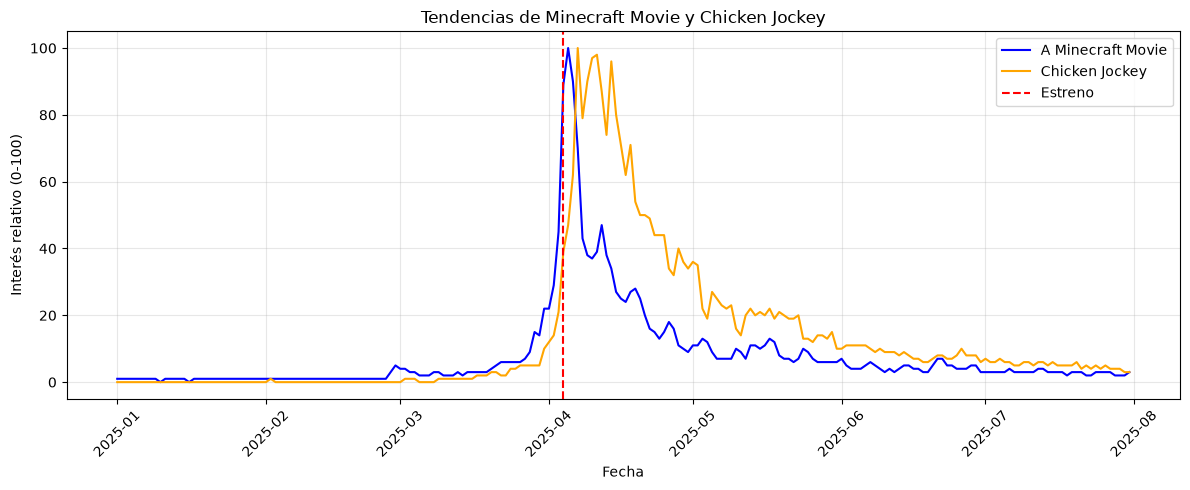

In [18]:
plt.figure(figsize=(12, 5))

# Línea de Minecraft
plt.plot(
    df["fecha"],
    df["interes"],
    label="A Minecraft Movie",
    color="blue"
)

# Línea de Chicken Jockey
plt.plot(
    df_chicken["fecha"],
    df_chicken["interes_chicken"],
    label="Chicken Jockey",
    color="orange"
)

# Fecha del estreno
plt.axvline(
    pd.Timestamp("2025-04-04"),
    color="red",
    linestyle="--",
    label="Estreno"
)

plt.title("Tendencias de Minecraft Movie y Chicken Jockey")
plt.xlabel("Fecha")
plt.ylabel("Interés relativo (0-100)")

plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Hallazgo 2 — Impacto de la conversación viral

El análisis de Google Trends evidencia que el interés de búsqueda por *A Minecraft Movie* y por el fenómeno *Chicken Jockey* aumentó considerablemente durante los primeros días de abril de 2025, coincidiendo con el estreno cinematográfico.

Mientras que la película alcanzó su máximo interés el 5 de abril, *Chicken Jockey* registró su punto máximo el 7 de abril, lo que refleja una rápida expansión del interés por este fenómeno.

Posteriormente, ambas tendencias disminuyeron, aunque se observaron repuntes secundarios.

**Interpretación para CineMetrics:** los fenómenos virales pueden constituir una oportunidad para ampliar la conversación digital alrededor de una producción cinematográfica. Sin embargo, estos datos no permiten demostrar que la viralización haya provocado un aumento de la recaudación.

In [19]:
# Buscar el registro de mayor interés de Minecraft
max_minecraft = df.loc[df["interes"].idxmax()]

# Buscar el registro de mayor interés de Chicken Jockey
max_chicken = df_chicken.loc[
    df_chicken["interes_chicken"].idxmax()
]

print("Máximo interés de Minecraft:")
print(max_minecraft)

print("\nMáximo interés de Chicken Jockey:")
print(max_chicken)

# Diferencia entre las fechas
diferencia = (
    max_chicken["fecha"] - max_minecraft["fecha"]
).days

print("\nDiferencia entre los picos:", diferencia, "días")

Máximo interés de Minecraft:
fecha      2025-04-05 00:00:00
interes                    100
Name: 94, dtype: object

Máximo interés de Chicken Jockey:
fecha              2025-04-07 00:00:00
interes_chicken                    100
Name: 96, dtype: object

Diferencia entre los picos: 2 días


In [20]:
# Cargar el archivo comparativo
ruta_compara = Path(
    r"C:\Codigo\GRUPO-6-CLASE-13-14\IMPTendencia\multiTimeline COMPARA (3).csv"
)

# Leer el CSV
comparacion = pd.read_csv(ruta_compara, skiprows=2)

# Renombrar las columnas
comparacion.columns = [
    "fecha",
    "minecraft",
    "chicken_jockey"
]

# Convertir las fechas
comparacion["fecha"] = pd.to_datetime(comparacion["fecha"])

# Limpiar y convertir los valores numéricos
for columna in ["minecraft", "chicken_jockey"]:
    comparacion[columna] = (
        comparacion[columna]
        .astype(str)
        .str.replace(r"<\s*1", "0", regex=True)
    )
    comparacion[columna] = pd.to_numeric(
        comparacion[columna],
        errors="coerce"
    )

# Ordenar cronológicamente
comparacion = comparacion.sort_values("fecha").reset_index(drop=True)

# Verificar los datos
print("Dimensiones:", comparacion.shape)
print("Valores nulos:")
print(comparacion.isnull().sum())

display(comparacion.head())

Dimensiones: (212, 3)
Valores nulos:
fecha             0
minecraft         0
chicken_jockey    0
dtype: int64


,fecha,minecraft,chicken_jockey
0,2025-01-01,1,0
1,2025-01-02,1,0
2,2025-01-03,1,0
3,2025-01-04,1,0
4,2025-01-05,1,0


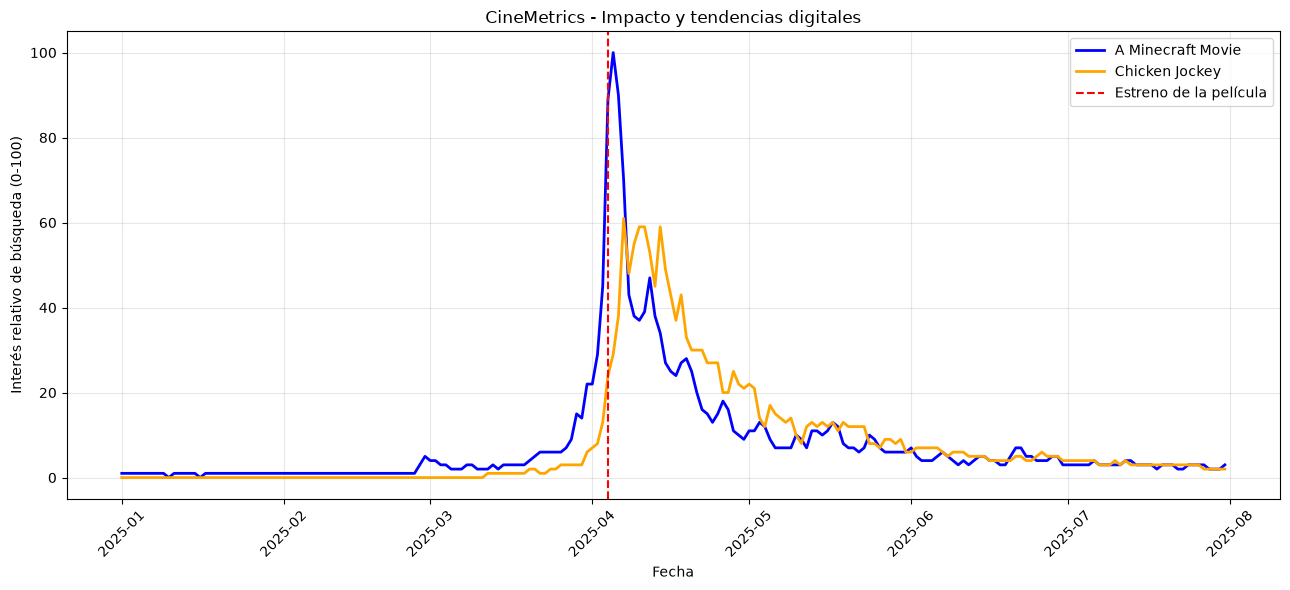

In [21]:
plt.figure(figsize=(13, 6))

# Tendencia de la película
plt.plot(
    comparacion["fecha"],
    comparacion["minecraft"],
    color="blue",
    linewidth=2,
    label="A Minecraft Movie"
)

# Tendencia del fenómeno viral
plt.plot(
    comparacion["fecha"],
    comparacion["chicken_jockey"],
    color="orange",
    linewidth=2,
    label="Chicken Jockey"
)

# Señalar estreno
plt.axvline(
    pd.Timestamp("2025-04-04"),
    color="red",
    linestyle="--",
    label="Estreno de la película"
)

plt.title("CineMetrics - Impacto y tendencias digitales")
plt.xlabel("Fecha")
plt.ylabel("Interés relativo de búsqueda (0-100)")

plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [22]:
periodo = comparacion[
    (comparacion["fecha"] >= "2025-04-10") &
    (comparacion["fecha"] <= "2025-04-14")
]

print("Promedios del 10 al 14 de abril:")
print(periodo[["minecraft", "chicken_jockey"]].mean().round(2))

Promedios del 10 al 14 de abril:
minecraft         39.0
chicken_jockey    55.0
dtype: float64


Hallazgo 2 — Evolución del fenómeno viral
La comparación de búsquedas de Google Trends evidencia que el interés por A Minecraft Movie alcanzó su máximo el 5 de abril de 2025, mientras que Chicken Jockey registró su máximo el 7 de abril.

Entre el 10 y el 14 de abril, el fenómeno viral presentó un interés relativo promedio superior al de la búsqueda de la película (55 frente a 39 puntos).

Implicancia para CineMetrics: los contenidos asociados a una película pueden mantener una conversación digital propia después del estreno. Esto representa una posible oportunidad para las estrategias de comunicación y marketing.

Explicación alternativa: parte de las búsquedas de Chicken Jockey podría provenir de personas interesadas en el videojuego Minecraft y no necesariamente en la película. Por lo tanto, se requiere contextualizar el fenómeno antes de atribuirlo exclusivamente al estreno.

FileNotFoundError: [Errno 2] No such file or directory: '../images/tendencias_minecraft.png'

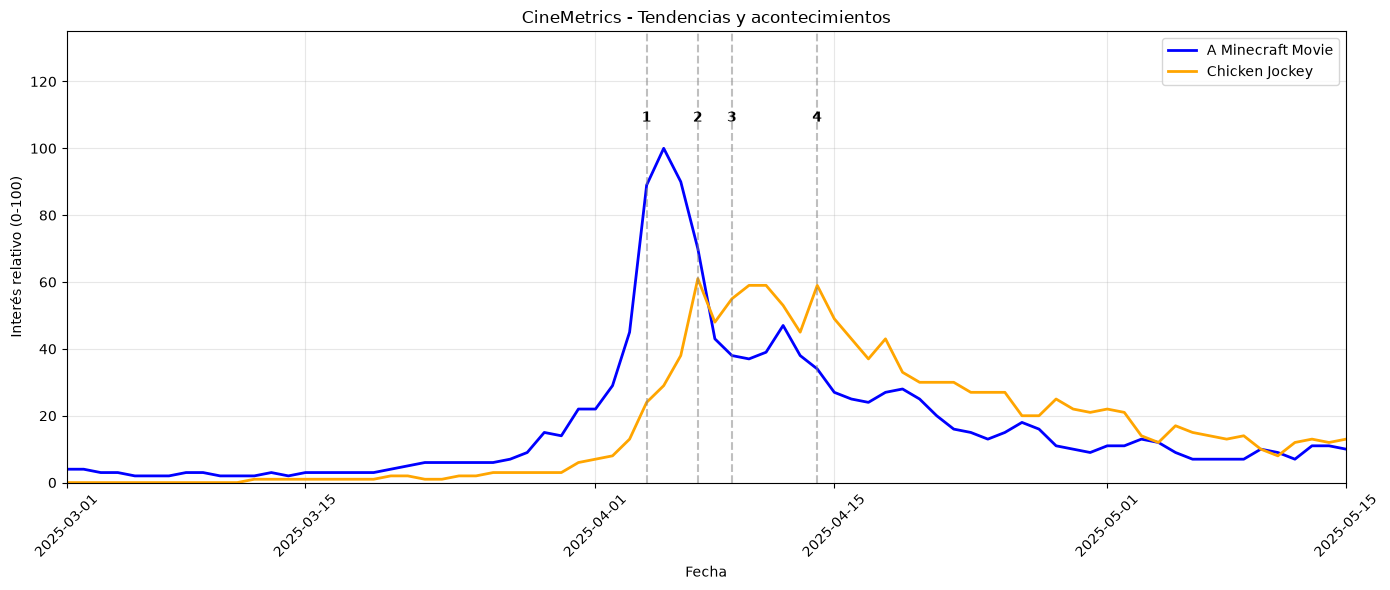

In [29]:
plt.figure(figsize=(14, 6))

plt.plot(
    comparacion["fecha"],
    comparacion["minecraft"],
    label="A Minecraft Movie",
    color="blue",
    linewidth=2
)

plt.plot(
    comparacion["fecha"],
    comparacion["chicken_jockey"],
    label="Chicken Jockey",
    color="orange",
    linewidth=2
)

# Acontecimientos documentados
eventos = [
    ("2025-04-04", "Estreno"),
    ("2025-04-07", "Cobertura viral"),
    ("2025-04-09", "Alertas en cines"),
    ("2025-04-14", "Jack Black")
]

for numero, (fecha, evento) in enumerate(eventos, start=1):
    fecha = pd.Timestamp(fecha)

    plt.axvline(
        fecha,
        color="gray",
        linestyle="--",
        alpha=0.5
    )

    plt.text(
        fecha,
        108,
        str(numero),
        fontsize=10,
        fontweight="bold",
        ha="center"
    )

plt.title("CineMetrics - Tendencias y acontecimientos")
plt.xlabel("Fecha")
plt.ylabel("Interés relativo (0-100)")
plt.ylim(0, 135)
plt.xlim(
    pd.Timestamp("2025-03-01"),
    pd.Timestamp("2025-05-15")
)

plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(
    "../images/tendencias_minecraft.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [ ]:
# Crear la carpeta para datos procesados
carpeta = Path("../data/processed")
carpeta.mkdir(parents=True, exist_ok=True)

# Guardar el dataset comparativo limpio
comparacion.to_csv(
    carpeta / "tendencias_minecraft_limpio.csv",
    index=False
)

print("Dataset limpio guardado correctamente")

Hallazgo 3 — Relación entre viralización y cobertura mediática
El crecimiento del interés por Chicken Jockey durante abril de 2025 coincide con la aparición de noticias sobre reacciones del público en las salas cinematográficas y su difusión en redes sociales.

La cobertura periodística del 7, 9 y 14 de abril permite contextualizar los picos registrados en Google Trends y demuestra que el fenómeno trascendió las búsquedas para convertirse en un acontecimiento de conversación pública.

Implicancia empresarial: CineMetrics podría considerar estrategias de marketing que faciliten la participación digital de los espectadores, aprovechando contenidos que surjan espontáneamente de sus producciones.

Limitación: no se puede establecer una relación causal entre la viralización y el incremento de la recaudación únicamente con datos de búsquedas.